In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#Стиль графа
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

#Генерация "грязного" датасета кредитных заявок
np.random.seed(42)
data = {
    "Loan_ID": [f"LP{1000+i}" for i in range(100)],
    "Gender": np.random.choice(
        ["Male", "Female", "MALE", "fem", None], 100, p=[0.4, 0.3, 0.1, 0.1, 0.1]
    ),
    "Married": np.random.choice(["Yes", "No", None], 100, p=[0.6, 0.3, 0.1]),
    "Dependents": np.random.choice(["0", "1", "2", "3+", None], 100),
    "ApplicantIncome": np.append(
        np.random.normal(5000, 1500, 95), [50000, 65000, 80000, 100000, 120000]
    ),  # 5 выбросов
    "LoanAmount": np.append(
        np.random.normal(150, 50, 90), [None] * 10
    ),  # 10 пропусков
    "Credit_History": np.random.choice([1.0, 0.0, None], 100, p=[0.7, 0.2, 0.1]),
    "Loan_Status": np.random.choice(["Y", "N"], 100),
}

df = pd.DataFrame(data)

# Добавляем 3 полные строки-дубликата
df = pd.concat([df, df.iloc[[0, 1, 2]]], ignore_index=True)

print(f"Размер исходных данных: {df.shape}")
df.head()

Размер исходных данных: (103, 8)


,Loan_ID,Gender,Married,Dependents,ApplicantIncome,LoanAmount,Credit_History,Loan_Status
0,LP1000,Male,Yes,3+,5224.750575,-18.204776,1.0,Y
1,LP1001,None,No,2,5211.361052,206.177089,1.0,Y
2,LP1002,MALE,Yes,0,5531.629378,257.160259,1.0,N
3,LP1003,Female,Yes,3+,2179.531117,132.870557,1.0,Y
4,LP1004,Male,None,3+,6449.588003,162.465727,1.0,Y


In [2]:
print("--- ИНФОРМАЦИЯ О ДАТАСЕТЕ ---")
df.info()

print(f"\nНайдено полных дубликатов строк: {df.duplicated().sum()}")
print("\n--- ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- ИНФОРМАЦИЯ О ДАТАСЕТЕ ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Loan_ID          103 non-null    object 
 1   Gender           93 non-null     object 
 2   Married          93 non-null     object 
 3   Dependents       86 non-null     object 
 4   ApplicantIncome  103 non-null    float64
 5   LoanAmount       93 non-null     object 
 6   Credit_History   96 non-null     object 
 7   Loan_Status      103 non-null    object 
dtypes: float64(1), object(7)
memory usage: 6.6+ KB

Найдено полных дубликатов строк: 3

--- ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ ---
Gender            10
Married           10
Dependents        17
LoanAmount        10
Credit_History     7
dtype: int64


In [3]:
# 1. Удаляем дубликаты
df_cleaned = df.drop_duplicates().copy()
print(f"Строк после удаления дубликатов: {len(df_cleaned)}")

# 2. Исправляем текстовые ошибки в колонке Gender
df_cleaned["Gender"] = df_cleaned["Gender"].str.lower().str.strip()
gender_map = {"male": "Male", "female": "Female", "fem": "Female"}
df_cleaned["Gender"] = df_cleaned["Gender"].map(gender_map)

print("\nКатегории Gender после исправления:")
print(df_cleaned["Gender"].value_counts(dropna=False))

Строк после удаления дубликатов: 100

Категории Gender после исправления:
Gender
Male      58
Female    33
NaN        9
Name: count, dtype: int64


In [4]:
# Заполняем категории Модой (мода самое частое)
for col in ["Gender", "Married", "Dependents", "Credit_History"]:
    mode_val = df_cleaned[col].mode()[0]
    df_cleaned[col] = df_cleaned[col].fillna(mode_val)

# Заполняем числовой признак Медианой
df_cleaned["LoanAmount"] = df_cleaned["LoanAmount"].fillna(df_cleaned["LoanAmount"].median())

print("Осталось не заполнено пропусков в датасете:", df_cleaned.isnull().sum().sum())

Осталось не заполнено пропусков в датасете: 0


/tmp/ipykernel_201211/905938469.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cleaned[col] = df_cleaned[col].fillna(mode_val)
/tmp/ipykernel_201211/905938469.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_cleaned["LoanAmount"] = df_cleaned["LoanAmount"].fillna(df_cleaned["LoanAmount"].median())


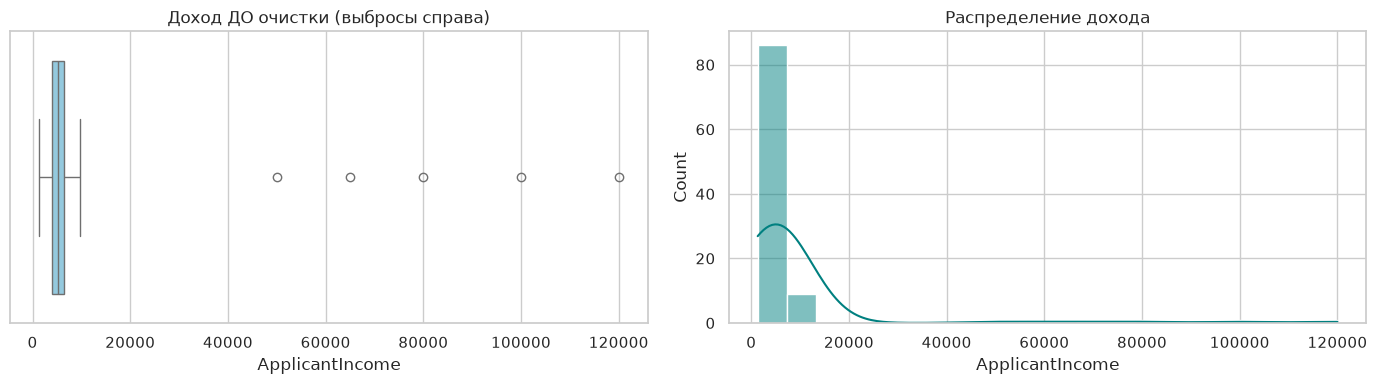

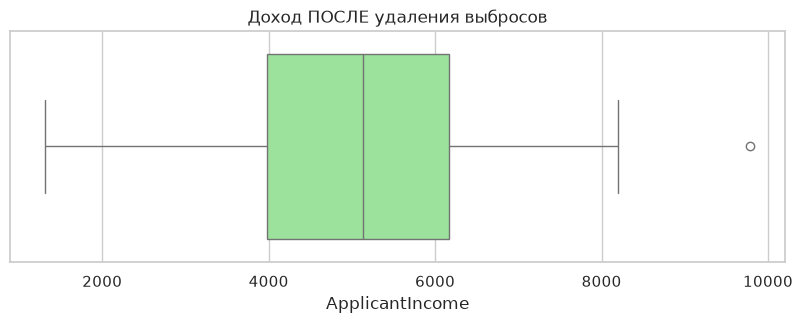

Размер датасета до удаления выбросов: 100
Размер датасета после удаления выбросов: 95


In [5]:
# 1. Показываем выбросы до очистки
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df_cleaned["ApplicantIncome"], ax=axes[0], color="skyblue").set_title("Доход ДО очистки (выбросы справа)")
sns.histplot(df_cleaned["ApplicantIncome"], kde=True, ax=axes[1], color="teal").set_title("Распределение дохода")
plt.tight_layout()
plt.show()

# 2. Математический расчет межквартильного размаха (IQR)
Q1 = df_cleaned["ApplicantIncome"].quantile(0.25)
Q3 = df_cleaned["ApplicantIncome"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Фильтрация
df_final = df_cleaned[(df_cleaned["ApplicantIncome"] >= lower_bound) & (df_cleaned["ApplicantIncome"] <= upper_bound)].copy()

# 3. Графа после очистки
plt.figure(figsize=(10, 3))
sns.boxplot(x=df_final["ApplicantIncome"], color="lightgreen").set_title("Доход ПОСЛЕ удаления выбросов")
plt.show()

print(f"Размер датасета до удаления выбросов: {len(df_cleaned)}")
print(f"Размер датасета после удаления выбросов: {len(df_final)}")

## Выводы

- Нашёл и убрал 3 полных дубликата строк.
- В колонке Gender были разные варианты написания (Male, MALE, fem и т.д.) — привёл к одному виду (Male/Female).
- Пропуски в категориальных колонках (Gender, Married, Dependents, Credit_History) заполнил модой (самым частым значением).
- Пропуски в LoanAmount заполнил медианой, чтобы выбросы меньше влияли на результат.
- В ApplicantIncome нашёл выбросы методом IQR (межквартильный размах) и убрал 5 строк с аномально высоким доходом.
